# DNN Workshop — from fitting data to designing a classifier

In the earlier workshop, we fitted a continuous waveform. Here, we want to recognise a category: **which digit does an image contain?**

## How to Proceed:

This notebook is intended to be run linearly, 1.1 --> 1.2 --> ..., --> 2 --> 3 --> ...

Any code expected for you to complete will contain `## FINISH_ME ##` indicating the code isn't expected to run until you have completed it.

### Today's Workshop

We will explore three choices:

| Choice | Experiment |
|---|---|
| Which model? | Compare decision trees with a neural network. |
| Which answer format? | Predict one number, ten class scores or four bits. |
| Which training objective? | Add loss terms to encourage valid answers. |

First, we prepare the gradients, data and measurements. Then, for each experiment: **predict the outcome, inspect the results, explain the behaviour**.

A lower training loss means better fitting to that objective. Validation results tell us whether the improvement transfers to unfamiliar images.


## 0. Setup

Run this cell first. It imports the libraries and sets the seeds, CPU threads and training settings used throughout the notebook.


In [2]:
import os
import random
from pathlib import Path

THREADS=1

os.environ.setdefault("OPENBLAS_NUM_THREADS", str(THREADS))  # Set before importing numerical libraries.
os.environ.setdefault("MKL_NUM_THREADS", str(THREADS))  # Set before importing numerical libraries.
os.environ.setdefault("OMP_NUM_THREADS", str(THREADS))  # Set before importing numerical libraries.

SEED = 12345  # Fixed seed for the data split, model weights and shuffled batches.
os.environ.setdefault("PYTHONHASHSEED", str(SEED))  # Set before importing numerical libraries.

# Import PyTorch before XGBoost to avoid a CPU-library conflicts
import torch
torch.set_num_threads(THREADS)  # PyTorch uses the requested threads independently
from torch import nn
from torch.utils.data import TensorDataset, DataLoader
from torchvision.datasets import MNIST
from xgboost import XGBClassifier
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
from matplotlib.ticker import MaxNLocator
from IPython.display import Markdown, display

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

plt.rcParams.update({"figure.dpi": 110, "font.size": 10})
BATCH_SIZE = 128         # Maximum number of images used in one parameter update.
EPOCHS = 30
FINAL_MODEL_EPOCHS = 60  # Section 7 gets a longer training run.
LEARNING_RATE = 0.0001


## 1. From a loss to parameter gradients

PyTorch applies the same chain rule that we used by hand. We will check it in three equivalent ways before building a classifier.

Use input $x=2$, target $y=5$, weight $w=3$ and bias $b=1$:

$$\hat y=wx+b,\qquad L=\tfrac12(\hat y-y)^2.$$

The gradients describe how changing each parameter changes the loss:

$$\frac{\partial L}{\partial w}=(\hat y-y)x=4,\qquad
\frac{\partial L}{\partial b}=\hat y-y=2.$$

**Before running:** predict the output and loss as well as the two gradients.


### 1.1 Store the parameters in tensors

A **tensor** stores numbers, much like a NumPy array. `requires_grad=True` tracks the calculations involving a parameter.

`backward()` calculates gradients and stores them in `.grad`. It does not update the parameters.


In [3]:
x = torch.tensor([[2.0]])       # Shape (1, 1): one example with one input value.
target = torch.tensor([[5.0]])
w = torch.tensor(3.0, requires_grad=True)  # Track how the loss depends on this weight.
b = torch.tensor(1.0, requires_grad=True)  # The bias needs a gradient too.

# Compute the loss and its gradients with respect to w and b.
prediction = w * x + b
loss = 0.5 * (prediction - target) ** 2  # Mean squared error loss.

loss.backward()  # Calculate gradients; this does not change w or b.
# .item() extracts a single Python number from a one-element tensor.
print("Prediction, loss, dL/dw, dL/db:", prediction.item(), loss.item(), w.grad.item(), b.grad.item())

Prediction, loss, dL/dw, dL/db: 7.0 2.0 4.0 2.0


### 1.2 Store the parameters in a layer

`nn.Linear(1, 1)` stores one weight and one bias. It calculates the same prediction as our first example.

Use `torch.no_grad()` while assigning the starting values: those assignments are setup, not part of the calculation we want to differentiate.


In [7]:
layer = nn.Linear(1, 1)  # One input, one output; weight and bias are created for us.
with torch.no_grad():     # Set starting values without recording these assignments.
    layer.weight.fill_(3.0)
    layer.bias.fill_(1.0)

prediction = layer(x)     # The layer calculates weight * x + bias.
loss = 0.5 * (prediction - target).square().mean()

# Compute the gradients of the loss with respect to the layer's weight and bias.
loss.backward()

print("Prediction, loss, dL/dw, dL/db:",
      prediction.item(), loss.item(), layer.weight.grad.item(), layer.bias.grad.item())

Prediction, loss, dL/dw, dL/db: 7.0 2.0 4.0 2.0


### 1.3 Store the layer in a model

`__init__` builds the model's layers. `forward` describes how the input passes through them. Calling `model(x)` runs that calculation.

Only the organisation has changed. This model still contains the same single neuron.


In [14]:
class OneNeuron(nn.Module):
    def __init__(self):
        super().__init__()           # Set up the PyTorch model machinery.
        self.linear = nn.Linear(1, 1)  # Store the layer as part of this model.

    def forward(self, x):
        return self.linear(x)        # Describe the path from input to prediction.


model = OneNeuron()
with torch.no_grad():
    model.linear.weight.fill_(3.0)    # Use the same parameters as the earlier examples.
    model.linear.bias.fill_(1.0)

prediction = model(x)                # Calls the model's forward method.
loss = 0.5 * (prediction - target).square().mean()
loss.backward()
print("Prediction, loss, dL/dw, dL/db:",
      prediction.item(), loss.item(), model.linear.weight.grad.item(), model.linear.bias.grad.item())

Prediction, loss, dL/dw, dL/db: 7.0 2.0 4.0 2.0


**Question:** Why should all three examples give the same gradients? Does the bias have a gradient?

Further reading: [PyTorch's autograd introduction](https://docs.pytorch.org/tutorials/beginner/basics/autogradqs_tutorial.html).


**Answer:**

We are running the same calculation of backpropagation but in different formats — the maths is identical 

## 2. Define the classification problem

MNIST pairs a **28 × 28 greyscale image** with a **digit label from 0 to 9**. Stored pixels range from 0 (black) to 255 (white).

Our input is the image; our target is its digit label. Inspect one example before choosing how a model should represent its answer.


In [16]:
# Reuse the local files if MNIST has already been downloaded.
mnist_train = MNIST("data", train=True, download=True)
mnist_test = MNIST("data", train=False, download=True)

image_index = 0  # Python counts from zero: this selects the first training image.
raw_image = mnist_train.data[image_index]

# Display some information about the dataset and the selected image.
# Hint: len() gives the number of items in a dataset, and .shape gives the dimensions of a tensor.
print("Number of Official training images:", len(mnist_train))
print("Number of Official test images:", len(mnist_test))

# Display the first training image and its label.
# Hint: use .shape and .dtype to get the shape and data type of a tensor, and .min() and .max() to get the pixel range.
print("One image: shape", tuple(raw_image.shape), "dtype", raw_image.dtype)
print("This image's pixel range:", raw_image.min().item(), "to", raw_image.max().item())
print("Label:", mnist_train.targets[image_index].item())

100%|██████████| 9.91M/9.91M [00:01<00:00, 8.31MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 323kB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 3.03MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 7.74MB/s]

Number of Official training images: 60000
Number of Official test images: 10000
One image: shape (28, 28) dtype torch.uint8
This image's pixel range: 0 to 255
Label: 5


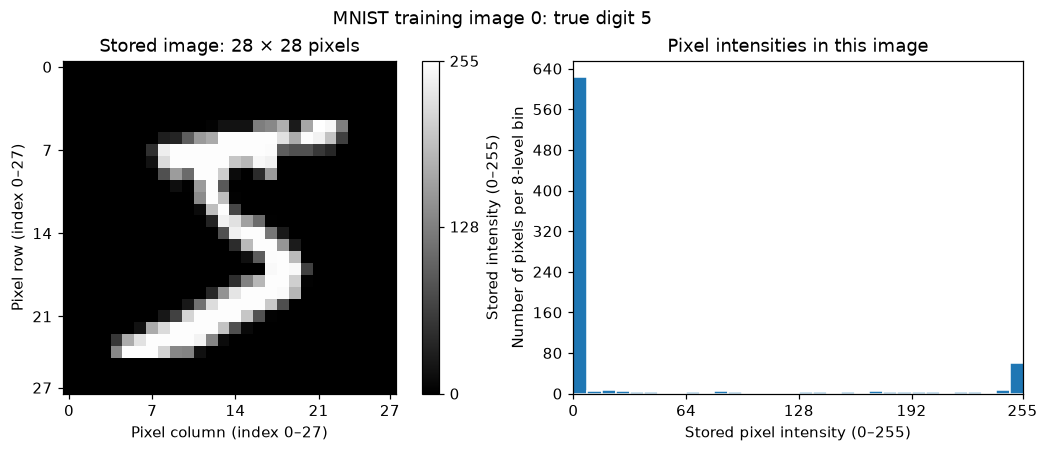

In [18]:
# Display the image and a histogram of its pixel intensities.
fig, axes = plt.subplots(1, 2, figsize=(10, 4), layout="constrained")

# Display the image with a colorbar and labeled axes.
fig.suptitle(f"MNIST training image {image_index}: true digit {mnist_train.targets[image_index].item()}")
pixels = axes[0].imshow(raw_image, cmap="gray", vmin=0, vmax=255,
                        origin="upper", interpolation="nearest")  # Keep individual pixels visible.
axes[0].set_title("Stored image: 28 × 28 pixels")
axes[0].set_xlabel("Pixel column (index 0–27)")
axes[0].set_ylabel("Pixel row (index 0–27)")
axes[0].set_xticks([0, 7, 14, 21, 27])
axes[0].set_yticks([0, 7, 14, 21, 27])
fig.colorbar(pixels, ax=axes[0], label="Stored intensity (0–255)", ticks=[0, 128, 255])

# The histogram counts all 784 pixels; each bin spans eight intensity levels.
axes[1].hist(raw_image.flatten().tolist(), bins=32, range=(0, 256), edgecolor="white")
axes[1].set_title("Pixel intensities in this image")
axes[1].set_xlabel("Stored pixel intensity (0–255)")
axes[1].set_ylabel("Number of pixels per 8-level bin")
# Hint: the x-axis should cover the full range of pixel intensities, and the y-axis should start at zero.
axes[1].set_xlim(0, 255)
axes[1].set_ylim(bottom=0)
axes[1].set_xticks([0, 64, 128, 192, 255])
axes[1].yaxis.set_major_locator(MaxNLocator(integer=True))

# show the figure in the notebook
plt.show()

### 2.1 Prepare one shared dataset split

Here we scale pixels to **0–1**. `unsqueeze(1)` adds a greyscale channel axis: `(images, 1, 28, 28)`.

Shuffle the 60,000 official training images into two sets. Keep the official test set separate.

| Set | Images | Purpose |
|---|---:|---|
| Training | 50,000 | Fit model parameters. |
| Validation | 10,000 | Judge learning and guide design choices. |
| Test | 10,000 | Evaluate the finished designs. |

Every model uses these same, non-overlapping sets. `TensorDataset` pairs images with labels; a `DataLoader` will later supply batches of those pairs.


In [20]:
# float() allows division; unsqueeze(1) adds the one-channel axis.
all_images = mnist_train.data.float().unsqueeze(1) / 255  # Scale pixel values to the range [0, 1].
all_labels = mnist_train.targets  # Keep labels as integers: 0, 1, ..., 9.

# Use a fixed random seed to shuffle the training images and labels in the same way each time.
split_generator = torch.Generator().manual_seed(SEED)

# Generate a random permutation of the indices of the training images. This will be used to split the dataset into training and validation sets.
# Hint: randperm() generates a random permutation of integers from 0 to n-1, where n is the number of images. The generator argument ensures reproducibility.
image_order = torch.randperm(len(mnist_train), generator=split_generator)  # Shuffle indices, not labels alone.

# Split the shuffled indices into training, validation, and test sets.
train_indices = image_order[:50_000]  # The first 50,000 images will be used for training.
validation_indices = image_order[50_000:60_000]  # The remaining 10,000 images.
# Use the same indices for images and labels so that each pair stays together.
train_images = all_images[train_indices]
train_labels = all_labels[train_indices]

# Use the same indices for images and labels so that each pair stays together.
validation_images = all_images[validation_indices]
validation_labels = all_labels[validation_indices]

test_images = mnist_test.data.float().unsqueeze(1) / 255.  # Apply the same pixel scaling.
test_labels = mnist_test.targets


print("Training:", tuple(train_images.shape))
print("Validation:", tuple(validation_images.shape))
print("Test:", tuple(test_images.shape))
print("Normalised range:", train_images.min().item(), "to", train_images.max().item())

Training: (50000, 1, 28, 28)
Validation: (10000, 1, 28, 28)
Test: (10000, 1, 28, 28)
Normalised range: 0.0 to 1.0


In [22]:
training_data = TensorDataset(train_images, train_labels)  # Each item is an (image, label) pair.

print("Number of training data:", len(training_data), "items, each with shape", tuple(training_data[0][0].shape))

Number of training data: 50000 items, each with shape (1, 28, 28)


**Question:** Why scale the pixels before training? Does this change which digit the image represents?


**Answer:**

It does not change the image but normalises the the inputs

## 3. How will we judge a classifier?

**Loss** measures the training objective. **Accuracy** counts correct digit predictions. A **confusion matrix** shows which digits are confused.

Each result figure has three panels:

1. Training and validation loss on a linear scale.
2. The same losses on a logarithmic scale.
3. The final test confusion matrix.

Read each matrix row as one true digit; columns are predicted digits. Rows total **100%**. These percentages describe groups of images, not probabilities for one image.

All matrices share a logarithmic colour scale; white means zero images. The following plotting helpers are supplied.


In [23]:
CONFUSION_NORM = LogNorm(vmin=0.01, vmax=100)  # Reuse one scale so colours mean the same in every matrix.
CONFUSION_COLOURS = plt.get_cmap("Blues").copy()
CONFUSION_COLOURS.set_bad("white")  # LogNorm masks zero counts; show those cells in white.

# Draw a confusion matrix on the given axes, using the given predictions and true labels.
def draw_confusion(ax, predictions, labels, title, include_invalid=False):

    number_of_columns = 11 if include_invalid else 10
    predicted_columns = predictions.clone()  # Keep the original predictions unchanged.
    predicted_columns[predicted_columns > 9] = 10  # Group codes 10–15 into the final column.

    # Give each (true digit, predicted column) pair a distinct index, then count the pairs.
    pair_indices = number_of_columns * labels + predicted_columns
    counts = torch.bincount(pair_indices, minlength=10 * number_of_columns)
    counts = counts.reshape(10, number_of_columns).float()  # Recover the rows and columns.
    percentages = 100 * counts / counts.sum(dim=1, keepdim=True)  # Divide by each row's total.

    plot = ax.imshow(percentages, norm=CONFUSION_NORM, cmap=CONFUSION_COLOURS,
                     interpolation="nearest")
    names = [str(digit) for digit in range(10)]
    if include_invalid:
        names.append("Invalid\n10–15")
    ax.set_xticks(range(number_of_columns), names, fontsize=9)
    ax.set_yticks(range(10))
    ax.set_xlabel("Predicted digit\nEach row totals 100%; white = 0 images")
    ax.set_ylabel("True digit")
    ax.set_title(title)

    def add_confusion_colourbar(plot):
        ticks = [0.01, 0.1, 1, 10, 100]  # Percentages, not fractions or raw image counts.
        colourbar = ax.figure.colorbar(plot, ax=ax, ticks=ticks)
        colourbar.set_label("Images within each true digit (%)\nLogarithmic colour scale")
        colourbar.ax.set_yticklabels(["0.01", "0.1", "1", "10", "100"])

    # Add a colourbar to the confusion matrix plot, showing the logarithmic scale of percentages.
    add_confusion_colourbar(plot)
    return plot



In [25]:
# Draw the training and validation loss curves on two axes, one linear and one logarithmic.
def draw_loss_curves(axes, steps, training_losses, validation_losses, loss_name, step_name):

    # Reuse the same loss values; change only how the vertical axis displays them.
    for ax, scale in zip(axes, ["linear", "log"]):

        # Draw the training and validation loss curves on the given axes, using the given loss values.
        ax.plot(steps, training_losses, label=f"Training ({len(train_labels):,} images)")
        ax.plot(steps, validation_losses, "--", label=f"Validation ({len(validation_labels):,} images)")
        ax.set_title("Loss (linear scale)" if scale == "linear" else "Loss (logarithmic scale)")

        # Label the axes, set the vertical scale, and add a grid and legend.
        ax.set_xlabel(step_name)
        ax.set_ylabel(loss_name)

        ax.set_yscale(scale)  # set the vertical scale to linear or logarithmic, depending on the current axes.
        if scale == "linear":
            ax.set_ylim(bottom=0)  # Show the size of the loss relative to zero.
        ax.set_xlim(steps[0], steps[-1])

        # Set the x-axis to show only integer step values, add a grid for the major y-ticks, and add a legend.
        ax.xaxis.set_major_locator(MaxNLocator(integer=True))
        ax.grid(axis="y", which="major", alpha=0.25)
        ax.legend(fontsize=9)


## 4. Establish a reference with decision trees

XGBoost combines trees that ask questions about pixel values. Each boosting round adds trees that help reduce the remaining errors.

Give it one row of **784 pixels per image**. Its ten class probabilities are assessed using **multiclass cross-entropy**, which rewards probability on the correct digit.

This establishes a reference before we try neural networks. First fit a depth-4 model; then examine how changing tree depth affects validation performance.

Further reading: [how XGBoost learns](https://xgboost.readthedocs.io/en/stable/tutorials/model.html).


In [26]:
# Keep one row per image; convert its 28 × 28 pixels into 784 features for XGBoost.
xgb_train_inputs = train_images.flatten(start_dim=1).numpy()
xgb_validation_inputs = validation_images.flatten(start_dim=1).numpy()
xgb_test_inputs = test_images.flatten(start_dim=1).numpy()

print("Training inputs:", xgb_train_inputs.shape, "dtype", xgb_train_inputs.dtype)
print("Validation inputs:", xgb_validation_inputs.shape, "dtype", xgb_validation_inputs.dtype)
print("Test inputs:", xgb_test_inputs.shape, "dtype", xgb_test_inputs.dtype)

Training inputs: (50000, 784) dtype float32
Validation inputs: (10000, 784) dtype float32
Test inputs: (10000, 784) dtype float32


In [29]:
# Build an XGBoost classifier with the given tree depth and other hyperparameters.
def build_tree_classifier(depth, learning_rate, n_estimators):
    return XGBClassifier(
        n_estimators=n_estimators, max_depth=depth, learning_rate=learning_rate,  # Rounds, tree size and update scale.
        objective="multi:softprob", eval_metric="mlogloss",   # Ten probabilities; measure cross-entropy.
        tree_method="hist", device="cpu", n_jobs=1, random_state=SEED,
        subsample=1.0, colsample_bytree=1.0,  # Use every training image and every pixel feature.
    )

# Build an XGBoost classifier with the given tree depth and other hyperparameters.
tree_model = build_tree_classifier(depth=4, learning_rate=0.15, n_estimators=80)

# Fit the XGBoost model to the training data, and evaluate it on both the training and validation sets.
_ = tree_model.fit(
    xgb_train_inputs, train_labels.numpy(),  # Only these examples are used to fit the model.

    eval_set=[(xgb_train_inputs, train_labels.numpy()),
              (xgb_validation_inputs, validation_labels.numpy())],  # Record both loss curves.
    verbose=True,
)

[0]	validation_0-mlogloss:1.89789	validation_1-mlogloss:1.90083
[1]	validation_0-mlogloss:1.64406	validation_1-mlogloss:1.65008
[2]	validation_0-mlogloss:1.45556	validation_1-mlogloss:1.46351
[3]	validation_0-mlogloss:1.30490	validation_1-mlogloss:1.31400
[4]	validation_0-mlogloss:1.17856	validation_1-mlogloss:1.18875
[5]	validation_0-mlogloss:1.07426	validation_1-mlogloss:1.08524
[6]	validation_0-mlogloss:0.98700	validation_1-mlogloss:0.99899
[7]	validation_0-mlogloss:0.90674	validation_1-mlogloss:0.91953
[8]	validation_0-mlogloss:0.84135	validation_1-mlogloss:0.85493
[9]	validation_0-mlogloss:0.78183	validation_1-mlogloss:0.79604
[10]	validation_0-mlogloss:0.73134	validation_1-mlogloss:0.74662
[11]	validation_0-mlogloss:0.68415	validation_1-mlogloss:0.70051
[12]	validation_0-mlogloss:0.64203	validation_1-mlogloss:0.65900
[13]	validation_0-mlogloss:0.60488	validation_1-mlogloss:0.62255
[14]	validation_0-mlogloss:0.57005	validation_1-mlogloss:0.58822
[15]	validation_0-mlogloss:0.54008	

In [31]:
# Evaluate the fitted XGBoost model on the test set and report its accuracy.
tree_predictions = torch.as_tensor(tree_model.predict(xgb_test_inputs)).long()  # Back to integer tensors.

# Calculate the test accuracy as the percentage of correct predictions.
tree_test_accuracy = 100 * (tree_predictions == test_labels).float().mean()  # Compare the predicted labels to the true labels, convert to float, and take the mean.
# Hint: Use the equality operator (==) to compare the predicted labels to the true labels, convert the resulting boolean tensor to float, and then take the mean of that tensor.

print(f"XGBoost test accuracy: {tree_test_accuracy:.2f}%")

XGBoost test accuracy: 95.88%


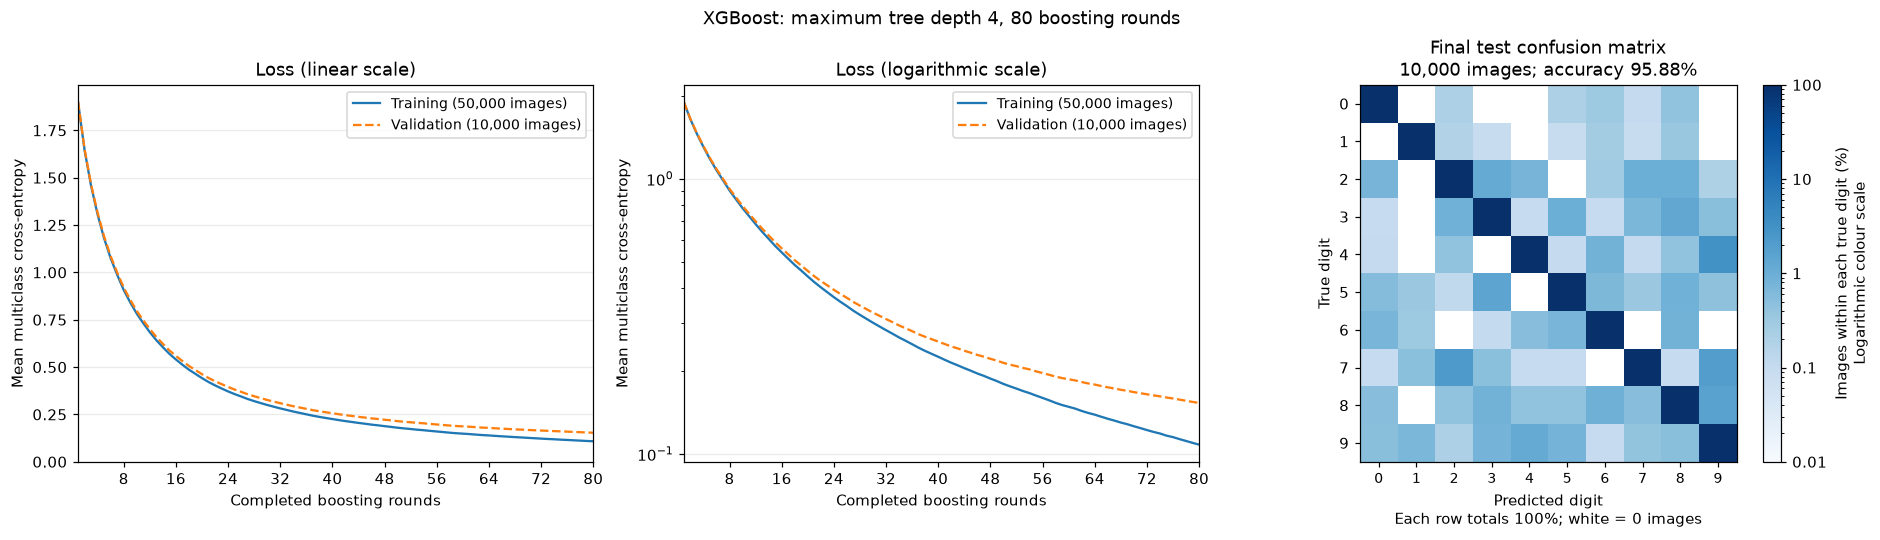

In [32]:
tree_history = tree_model.evals_result()
rounds = range(1, 81)  # XGBoost counts boosting rounds rather than neural-network epochs.
fig, axes = plt.subplots(1, 3, figsize=(17, 4.8), layout="constrained")
fig.suptitle("XGBoost: maximum tree depth 4, 80 boosting rounds")

# The first two panels share data; XGBoost names these histories by eval_set order.
draw_loss_curves(axes[:2], rounds,
                 tree_history["validation_0"]["mlogloss"], tree_history["validation_1"]["mlogloss"],
                 "Mean multiclass cross-entropy", "Completed boosting rounds")

matrix_title = f"Final test confusion matrix\n{len(test_labels):,} images; accuracy {tree_test_accuracy:.2f}%"
draw_confusion(axes[2], tree_predictions, test_labels, matrix_title)

# Show the figure in the notebook; the user can save it from the notebook interface.
plt.show()

### 4.1 Does a more flexible model help?

Keep **80 boosting rounds** and compare maximum depths **2, 4 and 6**. Fit new depth-2 and depth-6 models; reuse the fitted depth-4 model.

Deeper trees can describe more detailed patterns. Their depth controls successive decisions, not neural-network layers.

**Before running:** will greater depth improve training accuracy, validation accuracy, or both?

Further reading: [XGBoost parameters](https://xgboost.readthedocs.io/en/stable/parameter.html).


In [34]:
# Compare the training and validation accuracy of XGBoost models with different maximum tree depths.
tree_capacity_results = []
xgb_trees = {}
xgb_trees[4] = tree_model  # Store the fitted model for later use.

# Build and fit XGBoost models with maximum tree depths of 2 and 6, reusing the same hyperparameters as the depth-4 model.
for depth in [2, 6]:
    candidate = build_tree_classifier(depth, learning_rate=0.15, n_estimators=80)  # Reuse the model already fitted.
    candidate.fit(xgb_train_inputs, train_labels.numpy(), verbose=True)
    xgb_trees[depth] = candidate  # Store the fitted model for later use.

# Compare the training and validation accuracy of XGBoost models with different maximum tree depths.
for depth in [2, 4, 6]:
    candidate = xgb_trees[depth]  # Reuse the model already fitted.

    # Compare predictions on familiar training images and separate validation images.
    training_digits = torch.as_tensor(candidate.predict(xgb_train_inputs)).long()
    validation_digits = torch.as_tensor(candidate.predict(xgb_validation_inputs)).long()

    # Calculate the training and validation accuracy as percentages of correct predictions.
    train_accuracy = 100 * (training_digits == train_labels).float().mean().item()  # True/False becomes 1/0.
    validation_accuracy = 100 * (validation_digits == validation_labels).float().mean().item()

    tree_capacity_results.append((depth, train_accuracy, validation_accuracy))


In [35]:
# Each string below becomes one row of a Markdown table.
rows = ["| Maximum depth | Training accuracy | Validation accuracy |", "|---|---|---|"]
for depth, train_accuracy, validation_accuracy in tree_capacity_results:
    rows.append(f"| {depth} | {train_accuracy:.2f}% | {validation_accuracy:.2f}% |")
display(Markdown("\n".join(rows)))

| Maximum depth | Training accuracy | Validation accuracy |
|---|---|---|
| 2 | 91.33% | 90.68% |
| 4 | 97.68% | 95.74% |
| 6 | 99.88% | 97.05% |

**Question:** Which depth fits the training data best? Does it also perform best on validation data?


**Answer:** 

The increased depth (6) performs best on the training data

## 5. Build a neural network we can reuse

### 5.1 Keep the hidden-layer design the same

Every DNN uses:

**784 pixels → 128 neurons → 64 neurons → output layer**

`Flatten` puts the pixels in a row. `Linear` calculates weighted sums plus biases. `ReLU` replaces negative activations with zero. `Sequential` runs these operations in order.

Each model starts afresh with the same initial hidden weights. Those weights then learn separately. We will change the answer format and loss while reusing the training procedure.

The first output layer contains one neuron. Its loss and prediction rule are supplied below; we examine them in Section 6.


In [37]:
# Build a simple feed-forward neural network with two hidden layers and the given output size.
def build_dnn(output_size):
    torch.manual_seed(SEED)  # Recreate the same starting hidden-layer weights for each comparison.

    return nn.Sequential(

        nn.Flatten(),                                # (batch, 1, 28, 28) becomes (batch, 784).
        nn.Linear(784, 128), nn.ReLU(),        # First hidden layer, then its activation.
        nn.Linear(128, 64), nn.ReLU(),     # Second hidden layer, then its activation.
        nn.Linear(64, output_size),                  # Raw outputs: no rounding or probability conversion here.

    # Return the model to the CPU so that it can be used on any machine, even without a GPU.
    ).cpu()

# Define the loss function for the neural network, which calculates the mean squared error between the model's output and the true labels.
def number_loss(output, labels):
    estimates = output.squeeze(1)  # (batch, 1) becomes (batch,), matching the labels' shape.
    return nn.functional.mse_loss(estimates, labels.float())  # Average the squared numerical errors.

# Convert the neural network's raw outputs into integer predictions in the range 0–9.
def number_predictions(output):
    return output.squeeze(1).round().clamp(0, 9).long()  # Round, limit to 0–9, then convert to integers.

# Build a simple feed-forward neural network with two hidden layers and one output neuron for scalar regression.
scalar_model = build_dnn(output_size=1)
print(scalar_model)

Sequential(
  (0): Flatten(start_dim=1, end_dim=-1)
  (1): Linear(in_features=784, out_features=128, bias=True)
  (2): ReLU()
  (3): Linear(in_features=128, out_features=64, bias=True)
  (4): ReLU()
  (5): Linear(in_features=64, out_features=1, bias=True)
)


### 5.2 Update once per batch

A **batch** supplies examples for one parameter update. An **epoch** visits the whole training dataset.

With up to **128 images per batch**, our 50,000 training images require **391 updates per epoch**. The smaller final batch is included.

`train_batch` calculates predictions, measures the loss, calculates gradients and updates the parameters. `train_one_epoch` repeats this for every batch.


In [39]:
# Train the model on one batch of images and labels, updating its parameters based on the loss.
def train_batch(model, optimizer, loss_function, images, labels):

    optimizer.zero_grad()                 # Clear gradients left over from the previous batch.
    output = model(images)                # Forward pass: calculate predictions for this batch.
    loss = loss_function(output, labels)  # Compare those predictions with the targets.
    loss.backward()                       # Backward pass: calculate parameter gradients.
    optimizer.step()                      # Use the gradients to update weights and biases.

# Train the model for one epoch, iterating over all batches in the data loader.
def train_one_epoch(model, loader, optimizer, loss_function):
 
    model.train()                         # Select training mode; this line alone does not train.
    for batch_images, batch_labels in loader:         # Each iteration supplies the next batch of paired examples.
        train_batch(model, optimizer, loss_function, batch_images, batch_labels)

**Prepare training:** create a fresh batch loader, optimiser and loss history for each model. Reset the batch generator so their first 30 epochs use the same image order.

**AdamW** uses gradients to update parameters and applies weight decay to gently shrink weights. Here the learning rate is `0.0001` and weight decay is `0.001`.


In [40]:
# Prepare the data loader, optimizer, and history dictionary for training the model.
def prepare_training(model):
    torch.manual_seed(SEED)  # Reset any randomness used during training.

    loader = DataLoader(
        training_data, batch_size=BATCH_SIZE, shuffle=True,  # Shuffle again at the start of each epoch.
        generator=torch.Generator().manual_seed(SEED), num_workers=0,
    )  # By default the last smaller batch is included, so no training images are dropped.

    # Use the AdamW optimizer to update the model's parameters based on the calculated gradients.
    optimizer = torch.optim.AdamW(model.parameters(), lr=LEARNING_RATE, weight_decay=1e-3)
    history = {"epoch": [], "training": [], "validation": []}

    return loader, optimizer, history  # Return the three objects the training loop needs.

**Measure learning:** after each epoch, evaluate the current weights on all training and validation images. These measurements do not update parameters.

`model.eval()` selects evaluation behaviour. `torch.no_grad()` avoids recording calculations for back-propagation. They serve different purposes.


In [42]:
# Collect the model's outputs for all images, splitting them into smaller batches to limit memory usage during evaluation.
def collect_outputs(model, images):

    model.eval()                   # Set evaluation behaviour for layers that depend on the mode.
    outputs = []
    with torch.no_grad():          # We are measuring, so no gradients are needed.

        for batch in images.split(512):  # Use smaller groups to limit memory during evaluation.
            batch_output = model(batch)
            outputs.append( batch_output )

    return torch.cat(outputs)      # Join predictions in the same order as the input images.

In [44]:
def record_epoch(model, loss_function, history, epoch, total_epochs):
    # Measure both datasets with the current weights, without any further updates.
    training_output = collect_outputs(model, train_images)
    validation_output = collect_outputs(model, validation_images)

    # Calculate the training and validation loss as the mean squared error between the model's output and the true labels.
    training_loss = loss_function(training_output, train_labels).item()
    validation_loss = loss_function(validation_output, validation_labels).item()

    history["epoch"].append(epoch)                 # Save one point per completed epoch.
    history["training"].append(training_loss)
    history["validation"].append(validation_loss)

    # Print the current epoch and its training and validation loss, but only for the first epoch and every fifth epoch thereafter.
    if epoch == 1 or epoch % 5 == 0:              # % gives the remainder: print every fifth epoch.
        print(f"Epoch {epoch:2d}: training {training_loss:.5f} | validation {validation_loss:.5f}")
    if epoch == total_epochs:
        print(f"Finished {total_epochs} epochs")  # Keep variable wall-clock timings out of the results.

### 5.3 Reuse one training loop

The supplied loop has six lines. Prepare once, then repeat:

1. Update the model using every training batch.
2. Record training and validation losses.

We reuse this loop for each DNN. The first three run for **30 epochs**; the final experiment runs for **60**. The model, loss and training duration are the inputs to this loop.


In [45]:
def train_network(model, loss_function, epochs=EPOCHS):
    loader, optimizer, history = prepare_training(model)                 # Prepare once per model.
    for epoch in range(1, epochs + 1):                                   # Include the final epoch number.
        train_one_epoch(model, loader, optimizer, loss_function)         # Update on every batch.
        record_epoch(model, loss_function, history, epoch, epochs)       # Measure and store both losses.
    return history                                                       # Used to draw the loss curves.

### 5.4 Turn outputs into predictions

A **decoder** converts the model's raw outputs into digit predictions. Each answer format needs its own decoder.

The supplied helpers measure accuracy and draw the three result panels. Both loss panels use the same values; only the axis scale changes.

These experiments retain the **last epoch's weights**, not a checkpoint selected by validation loss. Compare loss values within an experiment; different loss functions measure different errors.


In [50]:
def evaluate_classifier(model, decoder):

    output = collect_outputs(model, test_images)
    predictions = decoder(output)  # Each output design needs its own rule for choosing a digit.

    accuracy = 100 * (predictions == test_labels).float().mean().item()  # Mean of 0/1 correctness flags.
    invalid_percent = 100 * (predictions > 9).float().mean().item()

    print(f"Test accuracy: {accuracy:.2f}% | Invalid predictions: {invalid_percent:.2f}%")
    return {"output": output, "predictions": predictions,
            "accuracy": accuracy, "invalid_percent": invalid_percent}


def show_result(history, result, title, loss_name, include_invalid=False):
    # Create a figure with three panels: linear loss, logarithmic loss, and confusion matrix.
    fig, axes = plt.subplots(1, 3, figsize=(17, 4.8), layout="constrained")
    fig.suptitle(f"{title} — {history['epoch'][-1]} training epochs")

    # axes[:2] selects the first two panels: linear loss and logarithmic loss.
    draw_loss_curves(axes[:2], history["epoch"], history["training"], history["validation"],
                     loss_name, "Completed training epochs")

    matrix_title = f"Final test confusion matrix\n{len(test_labels):,} images; accuracy {result['accuracy']:.2f}%"
    draw_confusion(axes[2], result["predictions"], test_labels, matrix_title, include_invalid)
    plt.show()

## 6. Can we classify by predicting a number?

Start with one numerical estimate per image. During training, fit it to the digit label. For classification, round the estimate and limit it to 0–9.

This decoder always returns an allowed digit, even if the raw estimate lies outside that range. But does numerical closeness describe a useful classification error?


### 6.1 Fit the numerical labels

**Mean squared error (MSE)** averages squared differences between the estimates and labels. Unlike Section 1's example, this loss has no factor of one half.

Training uses the real-valued estimate before rounding. The output is a number, not a probability.

**Before running:** could MSE fall while some digit predictions remain wrong?


In [51]:
# Train a scalar model to predict a single number.
scalar_model = build_dnn(output_size=1)  # Rebuild so rerunning this cell repeats the experiment.

# Hint the loss function was defined earlier as number_loss, which calculates the mean squared error between the model's output and the true labels.
scalar_history = train_network(scalar_model, loss_function= number_loss)  # Fit the one-output model with MSE.

# Evaluate the trained model on the test set, using the number_predictions function to convert outputs into integer predictions.
scalar_result = evaluate_classifier(scalar_model, number_predictions)  # Round only when predicting digits.

Epoch  1: training 4.23486 | validation 4.16957
Epoch  5: training 1.60154 | validation 1.62247
Epoch 10: training 0.94347 | validation 1.00117
Epoch 15: training 0.71922 | validation 0.81669
Epoch 20: training 0.61231 | validation 0.74218
Epoch 25: training 0.52323 | validation 0.68002
Epoch 30: training 0.45925 | validation 0.64185
Finished 30 epochs
Test accuracy: 69.62% | Invalid predictions: 0.00%


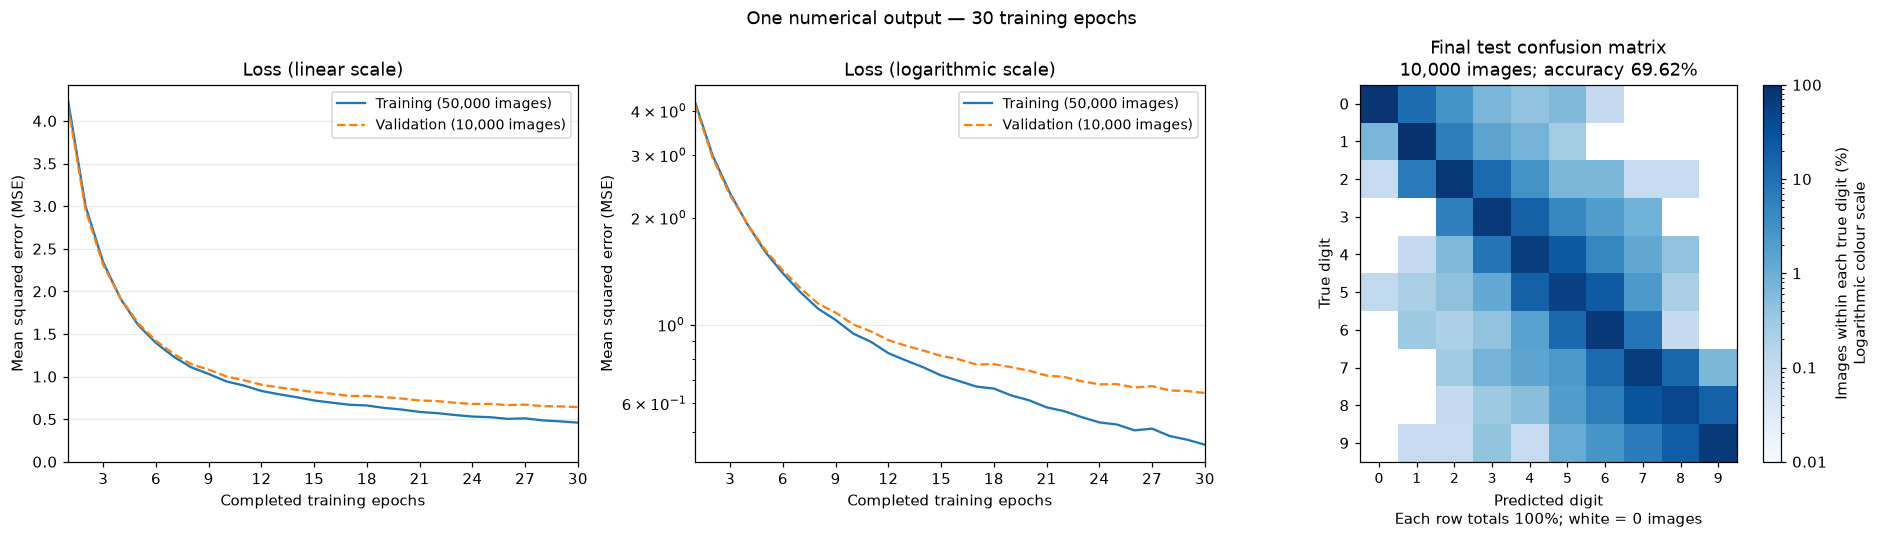

In [52]:
# Now plot the output from the training
show_result(scalar_history, scalar_result, "One numerical output", "Mean squared error (MSE)")

**Question:** What do the training and validation curves show? Does falling MSE guarantee better digit recognition?


**Answer:**

We see a discrepancy in training and validation, loss has not fully converged. Falling MSE gurantees better training but not necessarily digit recognition

**Question:** Why might the confusion matrix show a band around the diagonal?


**Answer:**

the model is confusing digits of similar value not shape as our output is in a single neuron

**Question:** What would a model that had not learned useful classification look like in the confusion matrix?


**Answer:**

If the model had not learned the confusion matrix would be a random mess

## 7. Represent the answer as a choice between classes

Numerical closeness can still give the wrong digit. Now give each digit its own score, so the loss rewards choosing the correct category.

A **one-hot target** contains one 1 and nine zeros. The model produces ten raw scores, or **logits**. Softmax converts them into probabilities that sum to one; the largest score selects the digit.

Use **categorical cross-entropy** with raw logits. It handles the probability calculation internally. Predictions need not be exact one-hot vectors.

Reference: [cross-entropy](https://docs.pytorch.org/docs/stable/generated/torch.nn.CrossEntropyLoss.html).


In [56]:
example_labels = torch.tensor([0, 6, 9])
print("Labels:", example_labels.tolist())
print("One-hot targets:\n", nn.functional.one_hot(example_labels, num_classes=10))

# Define the loss function for the neural network, which calculates the mean categorical cross-entropy between the model's output and the true labels.
def category_loss(output, labels):
    
    # Convert labels to one-hot encoding.
    # Hint: nn.functional.one_hot can be used to convert a vector of integer labels into one-hot encoded vectors.
    # The num_classes argument should be set to 10 for the MNIST dataset, which has 10 classes (digits 0-9).
    targets = nn.functional.one_hot(labels, num_classes=10).float()  # Convert labels to one-hot encoding and cast to float.

    return nn.functional.cross_entropy(output, targets)  # Pass logits; do not apply softmax first.

# Convert the neural network's raw outputs into integer predictions in the range 0–9.
def category_predictions(output):
    # Hint : Use torch.argmax to find the index of the maximum value along the class dimension (dim=1) for each image in the batch.
    # This index corresponds to the predicted class label.
    predictions = torch.argmax(output, dim=1)  # For each image, return the index of its largest class score.
    return predictions


Labels: [0, 6, 9]
One-hot targets:
 tensor([[1, 0, 0, 0, 0, 0, 0, 0, 0, 0],
        [0, 0, 0, 0, 0, 0, 1, 0, 0, 0],
        [0, 0, 0, 0, 0, 0, 0, 0, 0, 1]])


In [57]:
# Build a simple feed-forward neural network with two hidden layers and the given output size.
category_model = build_dnn(output_size=10)  # Only the final layer's width changes.

# Train the model on one batch of images and labels, updating its parameters based on the loss.
category_history = train_network(category_model, category_loss)

# Evaluate the trained model on the test set, using the category_predictions function to convert outputs into integer predictions.
category_result = evaluate_classifier(category_model, category_predictions)

Epoch  1: training 0.61630 | validation 0.60915
Epoch  5: training 0.28383 | validation 0.28188
Epoch 10: training 0.21716 | validation 0.22339
Epoch 15: training 0.16989 | validation 0.18154
Epoch 20: training 0.13663 | validation 0.15342
Epoch 25: training 0.11220 | validation 0.13396
Epoch 30: training 0.09378 | validation 0.12150
Finished 30 epochs
Test accuracy: 96.56% | Invalid predictions: 0.00%


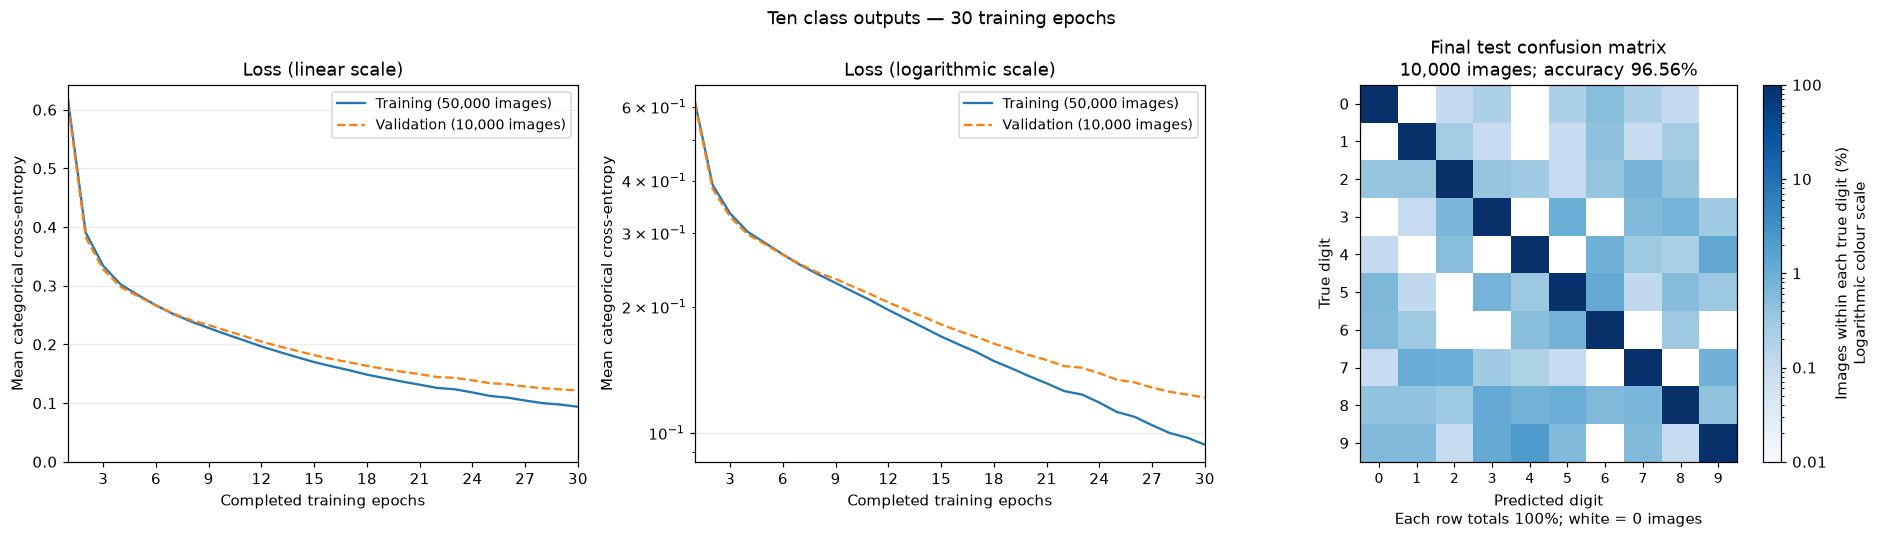

In [58]:
# Display the training history and evaluation results.
show_result(category_history, category_result, "Ten class outputs", "Mean categorical cross-entropy")

**Question:** How did changing the answer format affect accuracy and the pattern of errors?


**Answer:**

It greatly improved the accuracy as the information is not being forced into one output meaning we are not punished so harshly 


## 8. Represent the answer using four bits

Four bits can identify all ten digits. Their place values are **8, 4, 2 and 1**: digit 6 is `0110`, because 4 + 2 = 6.

Sigmoid converts each raw output into a bit probability. These four probabilities need not sum to one. Thresholding them gives a binary number.

This changes the meaning of the outputs while keeping the hidden-layer design. **Before running:** does using fewer outputs necessarily make the task easier?


In [ ]:
BIT_VALUES = torch.tensor([8, 4, 2, 1])  # Order of the four output columns, from largest bit to smallest.

def labels_to_bits(labels):
    columns = []
    for place_value in BIT_VALUES:
        columns.append((labels // place_value) % 2)  # Integer division and remainder extract this bit.
    return torch.stack(columns, dim=1).float()        # One row per image; four floating-point targets.


# Print the encoding so we can check what each training target means.
for digit, bits in zip(range(10), labels_to_bits(torch.arange(10)).int().tolist()):
    print(digit, "→", "".join(str(bit) for bit in bits))


# Define the loss function for the neural network, which calculates the mean squared error between the model's output and the true labels.
def binary_loss(output, labels):
    bit_targets = labels_to_bits(labels).float()  # Convert integer labels to bitwise representation.

    # Use the bitwise binary cross-entropy with logits so each of the four output bits is trained independently.
    return nn.functional.binary_cross_entropy_with_logits(output, bit_targets, reduction="mean")


def binary_predictions(output):
    bits = (output.sigmoid() >= 0.5).long()  # Turn each logit into a 0 or 1, after training.
    return (bits * BIT_VALUES).sum(dim=1)    # Convert each row of bits back to an integer.

0 → 0000
1 → 0001
2 → 0010
3 → 0011
4 → 0100
5 → 0101
6 → 0110
7 → 0111
8 → 1000
9 → 1001


### 8.1 Check the loss and count invalid answers

Four bits describe 16 integers. Codes **10–15** are invalid for MNIST and appear in an extra confusion-matrix column. `0000` is valid: it means zero.

**Current implementation:** `binary_loss` applies categorical CE to bit vectors, although the plot calls it BCE. Those targets are not categorical probability distributions. Independent bit decisions instead call for [bitwise BCE with logits](https://docs.pytorch.org/docs/stable/generated/torch.nn.BCEWithLogitsLoss.html).

Keep this loss/encoding mismatch in mind when interpreting the baseline. In particular, the all-zero target contributes zero to the current CE term.


In [ ]:

binary_model = build_dnn(output_size=4)  # The output size should match the number of bits used to represent the digits.

# Train the model on one batch of images and labels, updating its parameters based on the loss.
binary_history = train_network(binary_model, binary_loss)  # Fit the four-output model with bitwise BCE.
binary_result = evaluate_classifier(binary_model, binary_predictions)

show_result(binary_history, binary_result, "Four binary outputs", "Mean bitwise BCE", include_invalid=True)

AttributeError: 'NoneType' object has no attribute 'backward'

**Question:** What new difficulty does the four-bit representation introduce?

**Answer:**

`## FINISH_ME ##`

### 8.2 Express what we know about valid answers

We know that only codes 0–9 are allowed. Can we use that knowledge during fitting?

**Question:** How could we discourage invalid codes with a loss term that still provides useful gradients?


**Answer:**

`## FINISH_ME ##`

**Question:** Could a penalty reduce invalid answers while making digit recognition worse?


**Answer:**

`## FINISH_ME ##`

## 9. Use the loss to encourage desired behaviour

### 9.1 Give each loss term a purpose

Keep four outputs and change the training objective. This implementation combines:

- The existing categorical MSE term from Section 8.
- **Bitwise BCE**, with weight 1, to penalise incorrect bit probabilities.
- **Invalid-code probability**, with weight 10, to discourage codes 10–15.

As in a physics fit, a penalty expresses prior knowledge. Its weight controls the trade-off; improved behaviour must be checked on validation data.


In [ ]:
IMAGE_LOSS_WEIGHT = 1.0        # Strength of the normal image loss term.
INVALID_PENALTY_WEIGHT = 10.0  # Strength of the invalid-code term.
BCE_PENALTY_WEIGHT = 1.0       # Strength of the squared image-BCE term.


def invalid_probability(output):
    probabilities = output.sigmoid()  # Convert raw bit scores to probabilities before combining them.
    p8 = probabilities[:, 0]          # : selects every image; column 0 is the 8-bit.
    p4 = ## FINISH_ME ##
    p2 = ## FINISH_ME ##
    return p8 * (1 - (1 - p4) * (1 - p2))  # 8-bit on AND (4-bit on OR 2-bit on).


def bce_per_image(output, labels):
    # First convert the integer labels into four-bit vectors, then calculate the binary cross-entropy loss for each bit.
    targets = labels_to_bits(labels)

    # Hint: Use nn.functional.binary_cross_entropy_with_logits to compute the binary cross-entropy loss for each bit, without reducing (averaging) the losses.
    bit_losses = nn.## FINISH_ME ##(output, targets, reduction="none")
    
    return bit_losses.mean(dim=1)  # Keep one BCE per image by averaging only over its four bits.


def constrained_loss(output, labels):
    # Use the previously defined functions to compute the three components of the loss: label_loss, image_errors, and validity_loss.

    label_loss = binary_loss(output, labels).mean()                 # Ordinary cross-entropy loss for the batch of images and labels.
    image_errors = bce_per_image(output, labels).mean()             # Average the per-image BCE over the batch.
    validity_loss = invalid_probability(output).mean()              # Average the invalid-code probabilities over the batch.

    # Combine the THREE loss terms, weighting the image-BCE and invalid-code terms to control their influence on the total loss.
    # Make sure to use the constants defined above for the weights of the BCE and invalid-code terms.
    return ## FINISH_ME ##

### 9.2 Train the modified objective

Start a fresh four-output model with the same initial weights as Section 8. Run **60 epochs: 23,460 updates and 3 million image presentations**.

The first 30 epochs use the same batch order as the baseline. The extra 30 epochs double its training exposure.

The loss curves show the combined objective. The decoder still thresholds the four bit probabilities. Both the objective and training duration have changed.


In [ ]:
# Build a new model with the same architecture as the previous binary model, but with the constrained loss function.
constrained_model = build_dnn(output_size=4)  # Start fresh; do not continue the earlier model's weights.

# Train the constrained model on one batch of images and labels, updating its parameters based on the constrained loss function.
constrained_history = train_network(constrained_model, constrained_loss, epochs=FINAL_MODEL_EPOCHS)

# Evaluate the constrained model on the test set, using the same binary_predictions function to convert outputs into integer predictions.
constrained_result = evaluate_classifier(constrained_model, binary_predictions)  # Same thresholding rule as before.

In [ ]:
# Display the training history and evaluation results for the constrained model, which includes both the image-BCE and invalid-code penalties.
show_result(## FINISH_ME ##, ## FINISH_ME ##,
            "Four bits with both penalties", "Mean combined training loss", include_invalid=True)

### 9.3 Separate correctness from validity

Compare the **30-epoch baseline** with the **60-epoch modified model**. Accuracy measures correct digits; invalid-answer rate counts codes 10–15. Mean invalid probability measures probability assigned to those codes before thresholding.

**Table labels:** “BCE only” currently names the Section 8 baseline. “Test bitwise BCE” calls `binary_loss`, so it currently reports categorical CE on bit targets, not bitwise BCE.

Use the accuracy and invalid-answer columns to judge behaviour. These results alone cannot isolate the effects of the added terms from extra training.


In [ ]:
# Compare the two binary models: one trained with only the bitwise MSE loss, and the other trained with both the MSE and invalid-code penalties.

binary_comparison = {"MSE only": binary_result, "Both penalties": constrained_result}
comparison_epochs = {"MSE only": EPOCHS, "Both penalties": FINAL_MODEL_EPOCHS}
rows = ["| Model | Epochs | Test accuracy | Test bitwise MSE | Invalid test predictions | Mean invalid probability |",
        "|---|---|---|---|---|---|"]

# Calculate the test accuracy, bitwise BCE, invalid predictions, and mean invalid probability for each model, and add a row to the Markdown table for each model.
for name, result in binary_comparison.items():

    mse = binary_loss(result["output"], test_labels).item()  # Use the same plain MSE for both models.
    invalid_mass = 100 * invalid_probability(result["output"]).mean().item()
    rows.append(f"| {name} | {comparison_epochs[name]} | {result['accuracy']:.2f}% | {mse:.5f} "
                f"| {result['invalid_percent']:.2f}% | {invalid_mass:.3f}% |")

display(Markdown("\n".join(rows)))  # Join the table rows with newline characters.


In [ ]:
# Compare the test accuracy and invalid predictions of the two four-bit models using a bar chart.
fig, axes = plt.subplots(1, 2, figsize=(10, 4.5), layout="constrained")
fig.suptitle(f"Four-bit models on {len(test_labels):,} test images — different training budgets")

# The two metrics we want to compare are accuracy and invalid predictions, so we will create two bar charts, one for each metric.
metrics = ["accuracy", "invalid_percent"]
titles = ["Correct digit predictions", "Invalid predictions: codes 10–15"]

# Loop over the two axes, metrics, and titles simultaneously to create the bar charts for each metric.
for ax, metric, title in zip(axes, metrics, titles):

    values = [result[metric] for result in binary_comparison.values()]
    names = [f"{name}\n{comparison_epochs[name]} epochs" for name in binary_comparison]

    bars = ax.bar(names, values, color=["tab:purple", "tab:green"])
    ax.bar_label(bars, labels=[f"{value:.2f}%" for value in values], padding=3)
    ax.set_title(title)

    ax.set_xlabel("Training objective and number of epochs")
    ax.set_ylabel("Percentage of all test images (%)")
    ax.set_axisbelow(True)
    ax.grid(axis="y", alpha=0.25)

# Set the y-axis limits for both bar charts.
# The first chart shows accuracy, which is a percentage and should range from 0 to 100.
# The second chart shows the percentage of invalid predictions, which can vary based on the model's performance, so we set the upper limit to be slightly higher than the maximum observed value to ensure all bars fit within the chart.
axes[0].set_ylim(0, 100)  # Accuracy is a percentage; show the full 0–100 range.
axes[1].set_ylim(0, max(0.25, 1.3 * max(result["invalid_percent"] for result in binary_comparison.values())))

# Show the figure in the notebook; the user can save it from the notebook interface.
plt.show()

**Question:** Did accuracy improve, validity improve, or both? What comparison would identify which change helped?


**Answer:**

`## FINISH_ME ##`

## 10. What did each design achieve?

| Design | Main question |
|---|---|
| Decision trees | How does model flexibility affect generalisation? |
| One numerical output | Does numerical closeness give the correct class? |
| Ten class scores | Does choosing between categories help? |
| Four bit outputs | How do encoding and loss interact? |
| Added loss terms | Can we improve validity without sacrificing accuracy? |


### Compare the evidence

Accuracy measures the same outcome across all five models. Their training losses measure different things, so a smaller loss in one row does not establish a better classifier.

The first three DNNs train for **30 epochs**, the last for **60**. XGBoost uses **80 boosting rounds**, a different training procedure.

**Final question:** Which design would you choose, and what evidence supports it?

**Answer guide:** use validation performance to guide the choice, check any validity requirement, and report test results for the finished design. One fixed-seed experiment does not establish a universal winner.


In [ ]:
# Accuracy uses the same definition for all models, unlike their training losses.
summary_results = {
    "XGBoost (depth 4)": tree_test_accuracy,
    "DNN: one number": scalar_result["accuracy"],
    "DNN: ten classes": category_result["accuracy"],
    "DNN: four bits": binary_result["accuracy"],
    "DNN: four bits + both penalties (60 epochs)": constrained_result["accuracy"],
}

# List the models and their test accuracies in a Markdown table, which can be displayed in the notebook.
rows = ["| Model | Test accuracy |", "|---|---|"]
for name, score in summary_results.items():
    rows.append(f"| {name} | {score:.2f}% |")

# Show the summary table in the notebook; the user can save it from the notebook interface.
display(Markdown("\n".join(rows)))